# 04 — Modelagem por agrupamento

**CRISP-DM fase 4 — modelagem** · Turismo e Hotelaria

A entrada desta etapa é a matriz pré-processada produzida no notebook
`03-preparacao`. As variáveis numéricas foram normalizadas e as categorias
nominais foram codificadas com One-Hot Encoding.

Serão comparados algoritmos de agrupamento para identificar perfis naturais
de reservas hoteleiras. A variável `is_canceled` não participa da modelagem;
ela será utilizada somente na avaliação posterior dos segmentos.

Como a base possui 119.390 reservas, as métricas de distância serão calculadas
com amostras controladas quando necessário, evitando construir uma matriz
completa de distâncias entre todas as reservas.

In [1]:
import warnings
warnings.filterwarnings('ignore')  # silencia avisos de convergência

import json  # resumo do modelo selecionado, lido pelo 05
import time
from pathlib import Path

import joblib  # salva o modelo em disco
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist  # distâncias entre imóveis e centros
from sklearn.base import BaseEstimator, ClusterMixin, clone  # base para os modelos escritos aqui
from sklearn.cluster import (KMeans, MiniBatchKMeans, BisectingKMeans, Birch,
                             AgglomerativeClustering, MeanShift, DBSCAN, estimate_bandwidth)
from sklearn.decomposition import PCA  # branqueamento: euclidiana no espaço branqueado = Mahalanobis
from sklearn.metrics import silhouette_score  # coesão × separação dos grupos (−1 a 1)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import ParameterGrid  # todas as combinações de uma grade
from sklearn.neighbors import NearestNeighbors  # escala do raio do DBSCAN
from sklearn.pipeline import Pipeline

In [2]:
X = pd.read_csv('../data/processed/hotel_bookings_preprocessed.csv', sep=';')  # saída do 03: features prontas para o modelo
X = X.drop(columns=['preco_venda', 'subclasse'], errors='ignore')             # preço fica para avaliar os segmentos; subclasse é código, não medida
X = X.to_numpy(dtype=float)                                                   # matriz numérica para os algoritmos

df = pd.read_csv('../data/processed/hotel_bookings_tratado.csv', sep=';')  # base curada, usada só para descrever os segmentos

assert len(X) == len(df)  # as duas bases precisam estar alinhadas linha a linha
X.shape                   # imóveis × features

(119390, 98)

## Algoritmo adicional

Além dos algoritmos disponíveis no scikit-learn, será avaliado o K-Means com
distância Manhattan. Ele atribui cada reserva ao centro mais próximo usando
distância L1 e atualiza cada centro pela mediana dos registros do grupo.

O K-Medoids não será usado nesta base porque sua implementação exigiria uma
matriz completa de distâncias entre todas as reservas, inviável para 119.390
registros.

In [3]:
class KMedianas(BaseEstimator, ClusterMixin):
    """K-Means com distância Manhattan: atribui pela L1 e o centro vira a mediana."""

    def __init__(self, n_clusters=3, n_init=5, max_iter=100, random_state=42):
        self.n_clusters = n_clusters
        self.n_init = n_init
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        rng = np.random.default_rng(self.random_state)
        melhor = np.inf
        for _ in range(self.n_init):                                          # várias partidas; fica a de menor custo
            centros = X[rng.choice(len(X), self.n_clusters, replace=False)]  # centros iniciais sorteados entre os imóveis
            for _ in range(self.max_iter):
                rotulos = cdist(X, centros, 'cityblock').argmin(axis=1)      # cada imóvel vai ao centro mais próximo em L1
                novos = np.array([np.median(X[rotulos == g], axis=0) if (rotulos == g).any() else centros[g]
                                  for g in range(self.n_clusters)])           # a mediana minimiza a soma das distâncias L1
                if np.allclose(novos, centros):                              # centros parados: convergiu
                    break
                centros = novos
            dist = cdist(X, centros, 'cityblock')
            custo = dist.min(axis=1).sum()                                   # soma das distâncias L1 ao centro
            if custo < melhor:
                melhor, self.labels_, self.cluster_centers_ = custo, dist.argmin(axis=1), centros
        return self


# class KMedoides(BaseEstimator, ClusterMixin):
#     """Centro = um imóvel real (medoide): o de menor soma de distâncias ao próprio grupo."""

#     def __init__(self, n_clusters=3, n_init=5, max_iter=100, random_state=42):
#         self.n_clusters = n_clusters
#         self.n_init = n_init
#         self.max_iter = max_iter
#         self.random_state = random_state

#     def fit(self, X, y=None):
#         dist = cdist(X, X)                                                   # distância euclidiana entre todos os pares
#         rng = np.random.default_rng(self.random_state)
#         melhor = np.inf
#         for _ in range(self.n_init):
#             medoides = rng.choice(len(dist), self.n_clusters, replace=False)  # medoides iniciais sorteados
#             for _ in range(self.max_iter):
#                 rotulos = dist[:, medoides].argmin(axis=1)                   # cada imóvel vai ao medoide mais próximo
#                 novos = medoides.copy()
#                 for g in range(self.n_clusters):
#                     membros = np.flatnonzero(rotulos == g)
#                     if len(membros):                                         # novo medoide: menor soma de distâncias no grupo
#                         novos[g] = membros[dist[np.ix_(membros, membros)].sum(axis=1).argmin()]
#                 if np.array_equal(novos, medoides):                          # medoides parados: convergiu
#                     break
#                 medoides = novos
#             custo = dist[:, medoides].min(axis=1).sum()                      # soma das distâncias ao medoide
#             if custo < melhor:
#                 melhor, self.labels_, self.medoid_indices_ = custo, dist[:, medoides].argmin(axis=1), medoides
#         return self

## Escalas dos parâmetros

Os algoritmos Mean Shift e DBSCAN dependem da escala das distâncias.

Como a base possui 119.390 reservas, os parâmetros são estimados em uma
amostra reprodutível de até 20.000 registros. Essa amostra reduz o custo
computacional sem alterar a matriz completa usada posteriormente pelos modelos.

O posto efetivo da matriz também é estimado para configurar a redução
Mahalanobis.

In [4]:
# Estimativa das escalas em uma amostra controlada

RNG = np.random.default_rng(42)
TAMANHO_AMOSTRA_PARAMETROS = min(20_000, len(X))

indices_amostra = RNG.choice(
    len(X),
    size=TAMANHO_AMOSTRA_PARAMETROS,
    replace=False,
)

X_parametros = X[indices_amostra]

# Posto efetivo da matriz para a transformação de Mahalanobis.
s = np.linalg.svd(
    X_parametros - X_parametros.mean(axis=0),
    compute_uv=False,
)

posto = int(
    (s**2 > 1e-10 * s[0] ** 2).sum()
)

# Larguras usadas pelo Mean Shift.
larguras = sorted(
    {
        round(
            float(
                estimate_bandwidth(
                    X_parametros,
                    quantile=quantil,
                    n_samples=len(X_parametros),
                    random_state=42,
                )
            ),
            2,
        )
        for quantil in (0.1, 0.2, 0.3, 0.5)
    }
)

larguras = [largura for largura in larguras if largura > 0]

# Raios usados pelo DBSCAN, baseados na distância ao décimo vizinho.
vizinhos = NearestNeighbors(
    n_neighbors=11,
    n_jobs=-1,
).fit(X_parametros)

distancias_vizinhos = vizinhos.kneighbors(
    X_parametros,
    return_distance=True,
)[0][:, -1]

raios = [
    round(float(np.percentile(distancias_vizinhos, percentil)), 2)
    for percentil in (50, 70, 80, 90, 95)
]

raios = [raio for raio in raios if raio > 0]

print(f"Amostra usada: {len(X_parametros):,} reservas")
print(f"Posto efetivo: {posto} de {X.shape[1]} atributos")
print(f"Bandwidths do Mean Shift: {larguras}")
print(f"Raios do DBSCAN: {raios}")

assert posto >= 1
assert larguras
assert raios

Amostra usada: 20,000 reservas
Posto efetivo: 81 de 98 atributos
Bandwidths do Mean Shift: [2.75, 3.03, 3.2, 3.43]
Raios do DBSCAN: [1.43, 1.52, 1.75, 2.01, 2.08]


## Grade de modelos

Serão comparados algoritmos compatíveis com a dimensão da base hoteleira.
Foram excluídos K-Medoids e Ward porque suas implementações exigem memória
quadrática em relação ao número de reservas.

A grade testa diferentes quantidades de grupos, de 2 a 8, mantendo o mesmo
espaço pré-processado para todos os algoritmos.

In [16]:
k = [2, 3, 4, 5]  # quantidades de segmentos testadas

models = [  # (nome, algoritmo, grade de hiperparâmetros)
    ('k-means', KMeans(n_init=10, random_state=42), {'n_clusters': k, 'init': ['k-means++', 'random']}),
    ('mini batch k-means', MiniBatchKMeans(n_init=10, random_state=42), {'n_clusters': k, 'batch_size': [64, 128, 256]}),
    ('bisecting k-means', BisectingKMeans(random_state=42), {'n_clusters': k, 'bisecting_strategy': ['biggest_inertia', 'largest_cluster']}),
    ('birch', Birch(), {'n_clusters': k, 'threshold': [0.5, 1.0, 2.0]}),
    ('k-means manhattan', KMedianas(n_init=2, max_iter=30, random_state=42), {'n_clusters': k}),
    ('k-means mahalanobis', Pipeline([
        ('branqueamento', PCA(n_components=posto, whiten=True, svd_solver='full')),  # desconta a correlação entre variáveis
        ('kmeans', KMeans(n_init=10, random_state=42)),
    ]), {'kmeans__n_clusters': k}),
    ('gaussian mixture', GaussianMixture(reg_covar=1e-3, max_iter=200, random_state=42),
     {'n_components': k, 'covariance_type': ['full', 'diag']}),  # k gaussianas; reg_covar contorna a covariância singular do one-hot
    ('dbscan', DBSCAN(min_samples=10), {'eps': raios}),                   # k emerge do raio; quem fica fora da densidade é ruído (−1)
]

## Varredura dos modelos

Cada configuração é treinada na base completa. Para tornar a avaliação viável,
a silhueta é calculada em uma amostra fixa de até 10.000 reservas.

A amostra é usada somente para a métrica; os rótulos dos modelos continuam
sendo gerados para todas as reservas.

In [17]:
# Varredura dos modelos em amostra controlada

TAMANHO_AMOSTRA_MODELO = min(10_000, len(X))
rng_modelo = np.random.default_rng(42)

indices_modelo = rng_modelo.choice(
    len(X),
    size=TAMANHO_AMOSTRA_MODELO,
    replace=False,
)

X_modelo = X[indices_modelo]

linhas = []

for nome, modelo, grade in models:
    inicio_modelo = time.perf_counter()

    for params in ParameterGrid(grade):
        inicio = time.perf_counter()

        modelo_atual = clone(modelo).set_params(**params)
        labels = modelo_atual.fit_predict(X_modelo)

        validos = labels >= 0
        labels_validos = labels[validos]
        grupos = len(np.unique(labels_validos))

        if grupos >= 2:
            silhueta = silhouette_score(
                X_modelo[validos],
                labels_validos,
                metric="euclidean",
            )
        else:
            silhueta = np.nan

        maior_grupo = (
            np.bincount(labels_validos).max() / len(labels_validos)
            if validos.any()
            else np.nan
        )

        linhas.append(
            {
                "modelo": nome,
                "params": params,
                "grupos": grupos,
                "silhueta": silhueta,
                "maior_grupo": maior_grupo,
                "ruido": 1 - validos.mean(),
                "segundos": time.perf_counter() - inicio,
            }
        )

    print(
        f"{nome}: "
        f"{time.perf_counter() - inicio_modelo:.1f}s"
    )

varredura = pd.DataFrame(linhas)

print(f"Amostra usada: {len(X_modelo):,}")
print(f"Configurações avaliadas: {len(varredura)}")

varredura.sort_values(
    "silhueta",
    ascending=False,
).head()

k-means: 55.6s
mini batch k-means: 68.9s
bisecting k-means: 43.8s
birch: 122.7s
k-means manhattan: 23.5s
k-means mahalanobis: 33.1s
gaussian mixture: 80.7s
dbscan: 23.9s
Amostra usada: 10,000
Configurações avaliadas: 61


,modelo,params,grupos,silhueta,maior_grupo,ruido,segundos
3,k-means,"{'init': 'k-means++', 'n_clusters': 5}",5,0.125735,0.2681,0.0,7.527227
7,k-means,"{'init': 'random', 'n_clusters': 5}",5,0.125595,0.2637,0.0,6.622275
4,k-means,"{'init': 'random', 'n_clusters': 2}",2,0.124796,0.6353,0.0,6.245970
0,k-means,"{'init': 'k-means++', 'n_clusters': 2}",2,0.124796,0.6353,0.0,7.560049
20,bisecting k-means,"{'bisecting_strategy': 'biggest_inertia', 'n_c...",2,0.124796,0.6353,0.0,5.512873


In [18]:
aprovados = (
    varredura
    .query('2 <= grupos <= 8')    # faixa de segmentos que o negócio consegue operar
    .query('maior_grupo <= 0.9')  # um grupo com 90%+ da carteira não segmenta, só isola exceções
    .query('ruido <= 0.2')        # no máximo 20% dos imóveis sem grupo
    .sort_values('silhueta', ascending=False)
)
resumo = aprovados.drop_duplicates('modelo').set_index('modelo')  # melhor configuração de cada algoritmo
winner = resumo.index[0]                                         # maior silhueta entre os aprovados

display(resumo.style.format({'silhueta': '{:.3f}', 'maior_grupo': '{:.1%}', 'ruido': '{:.1%}', 'segundos': '{:.1f}'}))
print(f'Sem configuração aprovada: {sorted(set(varredura.modelo) - set(resumo.index)) or "nenhum"}')
print(f'Melhor modelo: {winner}')

,params,grupos,silhueta,maior_grupo,ruido,segundos
modelo,,,,,,
k-means,"{'init': 'k-means++', 'n_clusters': 5}",5,0.126,26.8%,0.0%,7.5
bisecting k-means,"{'bisecting_strategy': 'biggest_inertia', 'n_clusters': 2}",2,0.125,63.5%,0.0%,5.5
birch,"{'n_clusters': 3, 'threshold': 1.0}",3,0.121,60.4%,0.0%,8.7
mini batch k-means,"{'batch_size': 64, 'n_clusters': 5}",5,0.120,26.2%,0.0%,5.9
gaussian mixture,"{'covariance_type': 'diag', 'n_components': 4}",4,0.112,43.5%,0.0%,7.3
k-means manhattan,{'n_clusters': 5},5,0.104,34.5%,0.0%,5.9
k-means mahalanobis,{'kmeans__n_clusters': 5},5,0.016,53.6%,0.0%,8.2


Sem configuração aprovada: ['dbscan']
Melhor modelo: k-means


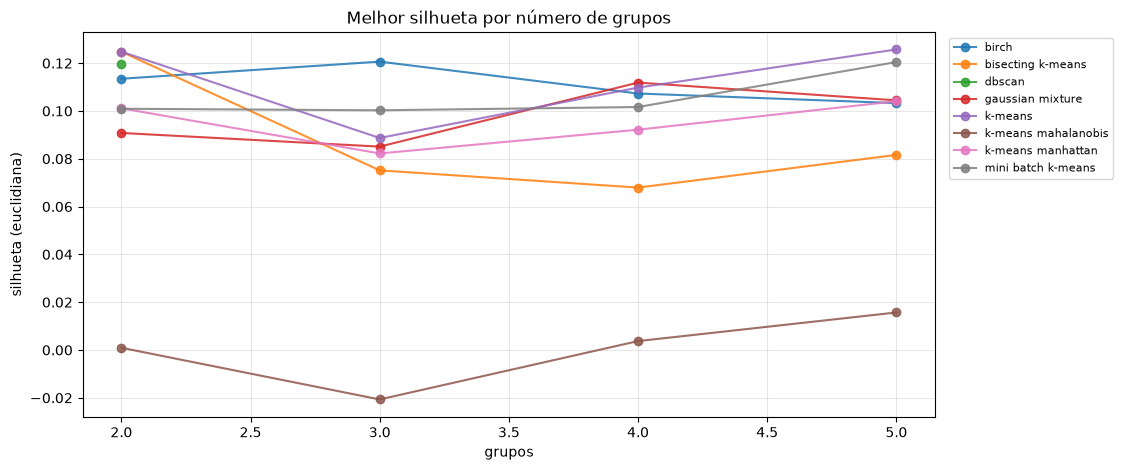

In [19]:
curvas = (
    varredura.query('2 <= grupos <= 10')                  # mean shift e dbscan podem gerar muitos grupos
    .groupby(['grupos', 'modelo'])['silhueta'].max()      # melhor silhueta de cada algoritmo por número de grupos
    .unstack('modelo')
)
ax = curvas.plot(marker='o', figsize=(11, 5), alpha=0.85)
ax.set(title='Melhor silhueta por número de grupos', xlabel='grupos', ylabel='silhueta (euclidiana)')
ax.grid(alpha=0.3)
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

In [20]:
modelo, params = dict((n, m) for n, m, _ in models)[winner], resumo.loc[winner, 'params']  # vencedor e seus hiperparâmetros
final = clone(modelo).set_params(**params)  # instância nova com a melhor configuração
labels = final.fit_predict(X)               # segmento final de cada imóvel (−1 = ruído, só no dbscan)

print(f'Parâmetros: {params}')
print(f'Silhueta: {resumo.loc[winner, "silhueta"]:.3f}')
print(f'Segmentos: {resumo.loc[winner, "grupos"]}')

Parâmetros: {'init': 'k-means++', 'n_clusters': 5}
Silhueta: 0.126
Segmentos: 5


In [21]:
# Perfil dos segmentos em unidades de negócio hoteleiras

perfil = (
    df.assign(segmento=labels)
    .groupby("segmento")
    .agg(
        reservas=("hotel", "size"),
        taxa_cancelamento=("is_canceled", "mean"),
        lead_time_mediano=("lead_time", "median"),
        noites_mediana=("total_nights", "median"),
        hospedes_mediana=("total_guests", "median"),
        adr_mediana=("adr", "median"),
        solicitacoes_mediana=("total_of_special_requests", "median"),
    )
    .assign(
        participacao=lambda tabela: tabela["reservas"] / len(df)
    )
    .sort_values("taxa_cancelamento", ascending=False)
)

perfil.style.format(
    {
        "taxa_cancelamento": "{:.1%}",
        "participacao": "{:.1%}",
        "lead_time_mediano": "{:.0f}",
        "noites_mediana": "{:.0f}",
        "hospedes_mediana": "{:.0f}",
        "adr_mediana": "{:.2f}",
        "solicitacoes_mediana": "{:.0f}",
    }
)

,reservas,taxa_cancelamento,lead_time_mediano,noites_mediana,hospedes_mediana,adr_mediana,solicitacoes_mediana,participacao
segmento,,,,,,,,
3,14451,99.7%,186,2,2,86.00,0,12.1%
2,32319,37.4%,57,3,2,99.00,1,27.1%
1,30113,30.3%,62,3,2,119.75,1,25.2%
0,24933,23.9%,99,3,2,79.00,0,20.9%
4,17574,15.1%,10,2,2,89.00,0,14.7%


In [23]:
# Salvando o modelo e os resultados da segmentação hoteleira

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

PASTA_MODELOS = RAIZ / "models"
PASTA_PROCESSADOS = RAIZ / "data" / "processed"

PASTA_MODELOS.mkdir(parents=True, exist_ok=True)
PASTA_PROCESSADOS.mkdir(parents=True, exist_ok=True)

nome_modelo = (
    winner
    .replace(" ", "_")
    .replace("-", "_")
)

modelo_path = PASTA_MODELOS / f"model_hotel_{nome_modelo}.joblib"

joblib.dump(final, modelo_path)

pd.DataFrame(
    {
        "segmento": labels,
    }
).to_csv(
    PASTA_PROCESSADOS / "segmentos.csv",
    sep=";",
    index=False,
)

perfil.to_csv(
    PASTA_PROCESSADOS / "perfil_segmentos.csv",
    sep=";",
    encoding="utf-8",
)

resumo_modelo = {
    "modelo": winner,
    "params": str(params),
    "grupos": int(resumo.loc[winner, "grupos"]),
    "silhueta": float(resumo.loc[winner, "silhueta"]),
    "arquivo": modelo_path.name,
}

(PASTA_MODELOS / "selecionado.json").write_text(
    json.dumps(
        resumo_modelo,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print(f"Modelo salvo em: {modelo_path}")
print("Rótulos salvos em: data/processed/segmentos.csv")
print("Perfil salvo em: data/processed/perfil_segmentos.csv")
print("Resumo salvo em: models/selecionado.json")

Modelo salvo em: /home/luan/Área de trabalho/projeto-hotel-clientes/projeto-exemplo-mercado-imobiliario-main/models/model_hotel_k_means.joblib
Rótulos salvos em: data/processed/segmentos.csv
Perfil salvo em: data/processed/perfil_segmentos.csv
Resumo salvo em: models/selecionado.json
